# M06-6（選讀）| weight_norm 在 QAT：訓練時保留 g、v，convert 前才從圖上拔掉

`weight_norm` 是什麼、export 之後長什麼樣、PTQ 怎麼處理，見 M05-5。
PTQ 不訓練，拿掉 weight_norm 沒有損失；QAT 要訓練，在 export 前 `remove_parametrizations` 就等於放棄訓練 $g$、$v$。
這本 notebook 看「保留到訓練結束」要怎麼做：

- **A.** 沒有 BN：$g$、$v$ 都有梯度、都在更新；convert 把 `_weight_norm` 折成常數，不需要額外處理。
- **B.** 有 BN：`prepare_qat_pt2e` 成功，`convert_pt2e` 在折 BN 時報 `ValueError`。
- **C.** 解法：訓練之後、convert 之前，用 `strip_weight_norm` 把 weight 改回 `get_attr`。

改圖的基本動作見 M00-4，QAT 的 conv + BN 子圖見 M04-2。

In [1]:
import copy

import torch

from common.models import ConvBnReLU, ConvReLU, example_inputs
from common.pt2e import convert_pt2e, export_module, prepare_qat_pt2e, quiet
from common.qat import freeze_for_eval, qat_quantizer
from common.viz import draw, draw_stages, table
from common.weight_norm import add_weight_norm, strip_weight_norm

quiet()
_ = torch.manual_seed(0)


def make(cls):
    """小模型，BN 先暖過幾個 batch，再對 conv.weight 套用 weight_norm。"""
    torch.manual_seed(0)
    m = cls(3, 8).train()
    with torch.no_grad():
        for _ in range(3):
            m(torch.randn(16, 3, 16, 16))
    add_weight_norm(m.eval())
    return m


def prepare(model):
    return prepare_qat_pt2e(export_module(model, example_inputs(), train=True), qat_quantizer(bits=8))


def short_train(prepared, steps=5):
    """幾步 SGD，只為了確認 g、v 會被更新；loss 隨便取。"""
    opt = torch.optim.SGD(prepared.parameters(), lr=1e-2)
    for _ in range(steps):
        opt.zero_grad()
        prepared(torch.randn(16, 3, 16, 16)).pow(2).mean().backward()
        opt.step()

`add_weight_norm`、`strip_weight_norm` 是本專案的工具（`common/weight_norm.py`），M05-5 介紹過；`qat_quantizer`、`freeze_for_eval` 見 M06-1、M06-2。

## A. 沒有 BN：g、v 都在訓練

conv + relu 套上 weight_norm 之後做 `prepare_qat_pt2e`：

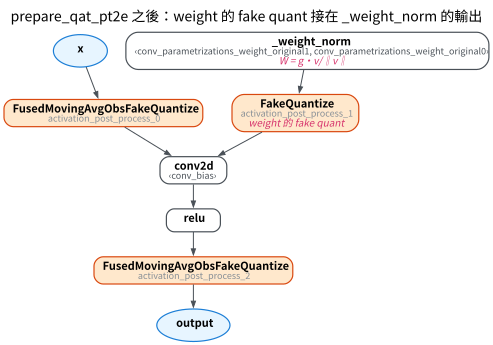

In [2]:
p = prepare(make(ConvReLU))
NOTES = {"_weight_norm": "W = g·v/‖v‖", "activation_post_process_1": "weight 的 fake quant"}
draw(p, title="prepare_qat_pt2e 之後：weight 的 fake quant 接在 _weight_norm 的輸出", notes=NOTES)

weight 的 fake quant 接在 `_weight_norm` 的輸出上，量化的是算出來的 $W$，和 PTQ 的 observer 位置相同（M05-5）。
訓練幾步，看哪些參數有梯度、有更新：

In [3]:
params = dict(p.named_parameters())
before = {k: v.detach().clone() for k, v in params.items()}
short_train(p)
updated = {k: (v.grad is not None and bool(v.grad.abs().sum() > 0), not torch.equal(v, before[k])) for k, v in params.items()}
table([[k, g, u] for k, (g, u) in updated.items()], ["參數", "有梯度", "有更新"])

參數,有梯度,有更新
conv.bias,True,True
conv.parametrizations.weight.original0,True,True
conv.parametrizations.weight.original1,True,True


In [4]:
assert all(g and u for g, u in updated.values())
assert any("original0" in k for k in updated) and any("original1" in k for k in updated)

`original0` 是 $g$、`original1` 是 $v$。STE 的梯度穿過 fake quant，再經 `_weight_norm` 傳回 $g$、$v$，所以 QAT 期間訓練的是 $g$ 與 $v$，re-parametrization 仍然有效。

沒有 BN 時，convert 不需要額外處理：

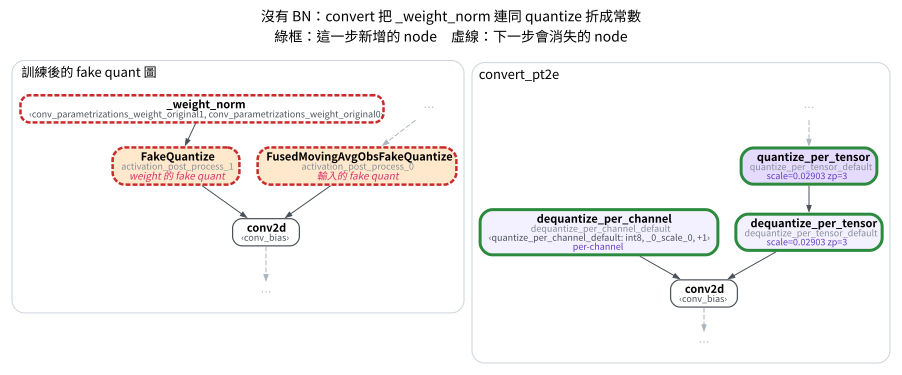

In [5]:
freeze_for_eval(p)
c = convert_pt2e(copy.deepcopy(p))
draw_stages([(p, "訓練後的 fake quant 圖"), (c, "convert_pt2e")],
            focus=["_weight_norm", "activation_post_process_0", "activation_post_process_1", "conv2d"], hops=0,
            notes=[{"activation_post_process_0": "輸入的 fake quant", "activation_post_process_1": "weight 的 fake quant"}, {}],
            title="沒有 BN：convert 把 _weight_norm 連同 quantize 折成常數")

In [6]:
assert "_weight_norm" not in {n.name for n in c.graph.nodes}

左圖的兩個 fake quant，在 convert 之後各換成不同的東西：

- **輸入的 fake quant** → `quantize_per_tensor` + `dequantize_per_tensor`：輸入的值要到執行時才知道，q/dq 留在圖上（右圖上方那兩個綠框）。
- **weight 的 fake quant 連同 `_weight_norm`** → 一個 int8 常數 + `dequantize_per_channel`：`_weight_norm` 的輸入全是常數，convert 預設 `fold_quantize=True`，把它連同 weight 的 quantize 一起預先算成 int8 常數（和 M05-5 B 段相同），所以右圖只剩 dequantize。

## B. 有 BN：prepare 成功，convert 失敗

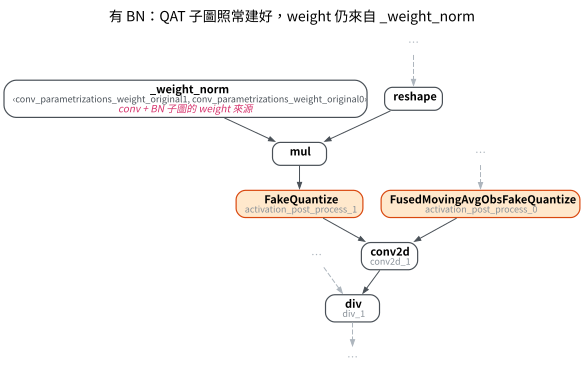

In [7]:
p_bn = prepare(make(ConvBnReLU))
FOCUS = ["_weight_norm", "mul", "activation_post_process_1", "conv2d_1"]
draw(p_bn, focus=FOCUS, hops=1, notes={"_weight_norm": "conv + BN 子圖的 weight 來源"},
     title="有 BN：QAT 子圖照常建好，weight 仍來自 _weight_norm")

`prepare_qat_pt2e` 不折 BN，而是把 conv + BN 換成 QAT 子圖（M04-2）：weight 先乘上 BN 的係數（`mul`）再進 fake quant。
建子圖的 pattern 比對不管 weight 從哪裡來，所以接 `_weight_norm` 也建得起來，訓練照常。問題在最後一步：

In [8]:
short_train(p_bn)
freeze_for_eval(p_bn)
try:
    convert_pt2e(copy.deepcopy(p_bn))
    error = None
except ValueError as e:
    error = e
print("convert_pt2e →", f"{type(error).__name__}: {error}")
assert error is not None

convert_pt2e → ValueError: Expected get_attr node, got call_function


`convert_pt2e` 要真的把 BN 折進 conv（`_fold_conv_bn_qat`，M02-3 的五步之一），得把 weight 當常數讀出來改寫。
讀常數的 torchao 內部函式只接受 `get_attr`（讀 torchao 0.18 原始碼），weight 是 `_weight_norm` 這個 `call_function` 時就報錯。
和 PTQ 的差別是報錯的時機：PTQ 在 `prepare_pt2e` 一開始就報（M05-5），QAT 要到訓練全部做完、convert 時才報。

## C. 解法：訓練之後、convert 之前，把 weight 改回 get_attr

`strip_weight_norm(gm)` 用圖上同一顆 `_weight_norm`、同一組 $g$、$v$ 算出 weight，存成參數、插一個 `get_attr` node，`replace_all_uses_with` 讓下游改接它，再刪掉 `_weight_norm`（M00-4 的改圖動作）：

拔掉的 weight： ['conv.weight']
strip 之後的參數： ['conv.weight', 'bn.weight', 'bn.bias']


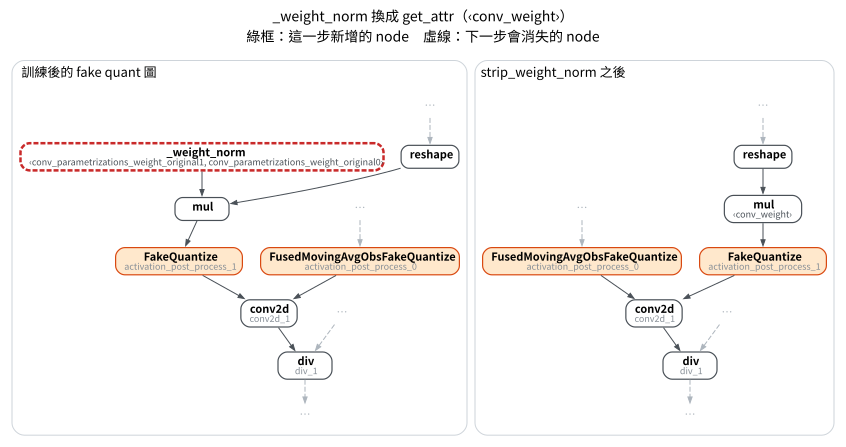

In [9]:
fixed = copy.deepcopy(p_bn)
x = torch.randn(32, 3, 16, 16)
with torch.no_grad():
    y_before = fixed(x)
print("拔掉的 weight：", strip_weight_norm(fixed))
print("strip 之後的參數：", [n for n, _ in fixed.named_parameters()])
draw_stages([(p_bn, "訓練後的 fake quant 圖"), (fixed, "strip_weight_norm 之後")], focus=FOCUS, hops=1,
            title="_weight_norm 換成 get_attr（‹conv_weight›）")

圖上 `mul` 的 weight 輸入變成 `‹conv_weight›`。現在可以 convert，BN 也折進 conv 了：

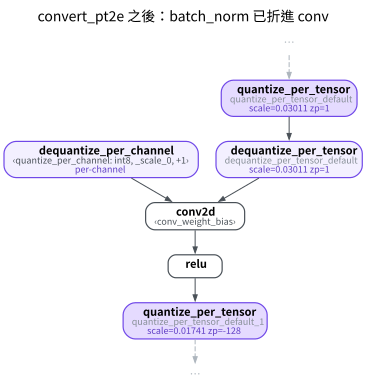

In [10]:
converted = convert_pt2e(copy.deepcopy(fixed))
draw(converted, focus=lambda n: n.name.startswith("conv2d"), hops=2, title="convert_pt2e 之後：batch_norm 已折進 conv")

In [11]:
with torch.no_grad():
    y_after, y_conv = fixed(x), converted(x)
checks = {"strip 前 vs 後的 fake quant 圖（torch.equal）": torch.equal(y_before, y_after),
          "strip 後的 fake quant 圖 vs convert 圖（torch.allclose）": torch.allclose(y_after, y_conv)}
table([[k, v] for k, v in checks.items()], ["同一批 32 筆輸入的輸出", "結果"])

同一批 32 筆輸入的輸出,結果
strip 前 vs 後的 fake quant 圖（torch.equal）,True
strip 後的 fake quant 圖 vs convert 圖（torch.allclose）,True


In [12]:
assert all(checks.values())
assert not any("batch_norm" in str(n.target) for n in converted.graph.nodes)

兩項檢查各查一件事：

- **strip 前後逐位元相同**：查改圖有沒有接錯。weight 是用同一顆 op、同一組 $g$、$v$ 算的，數值必然相同；會出錯的是新的 `get_attr` 指到哪個參數、下游是否都改接過去。
- **convert 圖和 fake quant 圖一致**：B 段在這一步失敗，這裡跑得完，而且輸出一致，表示折 BN 讀到的是正確的 weight。

為什麼要在訓練**之後**才拔：拔掉之後圖上只剩 $W$ 這個常數，訓練前呼叫就等於 `remove_parametrizations`，放棄訓練 $g$、$v$。

## 小結

- QAT 時 fake quant 接在 `_weight_norm` 的輸出上，梯度經它傳回 $g$、$v$。
- 沒有 BN 不必處理；有 BN 時 `prepare_qat_pt2e` 能過，`convert_pt2e` 折 BN 才報錯。
- 流程：`export(train=True)` → `prepare_qat_pt2e` → 訓練 → `freeze_for_eval` → `strip_weight_norm` → `convert_pt2e`。
- 這裡沒有比較 weight_norm 對 QAT 精度的影響。